# TP 2 — Nettoyer, imputer, visualiser : `clients_brut.csv` — **CORRIGÉ ENSEIGNANT**
**Analyse de données — Master IA / Master RSD** · Chapitre 2 : Exploration et préparation des données

*Nettoyer, imputer, visualiser : le cycle complet sur un cas concret.*

**Objectifs du TP**
1. **Nettoyer** un jeu de données brut : détecter et corriger les doublons, les incohérences et les problèmes de format → *données fiables prêtes à l'analyse*.
2. **Traiter les valeurs manquantes** : appliquer plusieurs méthodes d'imputation et comparer leurs impacts → *choisir la méthode la plus pertinente*.
3. **Visualiser** les données avec Matplotlib et Seaborn → *comprendre et communiquer*.
4. **Documenter chaque décision** (choix, justifications, résultats) dans ce notebook → *traçabilité et reproductibilité*.

| Volume | Organisation | Données | Livrable |
|---|---|---|---|
| 2 séances de 2 h (4 h au total) | Binômes · Notebook Jupyter | `clients_brut.csv` (fictif, fourni) | Notebook complété + conclusions |

**Prérequis mobilisés :** exploration du chapitre 1 (TP 1) et méthodes des sections 4 à 7 du chapitre 2.

⭐ **Continuité :** ce TP prolonge le TP 1 — même jeu de données (`clients.csv`), en version « brute » avec défauts injectés.

⚠️ **Ordre des opérations (à respecter)** : ① Dédupliquer → ② Harmoniser → ③ Typer → ④ Valider les plages. Cet ordre évite d'introduire des erreurs dans les étapes suivantes.

**Mode d'emploi** : complétez les cellules marquées `# TODO`, puis exécutez la cellule **✅ Auto-correction** qui suit. Répondez aux questions dans les cellules **✍️**.

## Partie 0 — Génération du jeu de données (enseignant)
`clients_brut.csv` est construit à partir du `clients.csv` du TP 1 (1 000 clients, 37 NaN dans `revenu`, 1 revenu aberrant à 999 999).
Défauts injectés, avec une graine fixe :
- **12 âges invalides** : 4 textes illisibles (`"trente"`, `"?"`, `"45 ans"`, `"inconnu"`) et 8 valeurs hors plage (150, −3, 999…) ;
- **60 segments en minuscules** (`a`, `b`) → incohérence de modalités ;
- **12 doublons exacts**, puis mélange des lignes.

Résultat attendu après nettoyage : **(988, 8)**, comme sur la diapositive.

In [1]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(2027)              # graine fixe -> fichier identique à chaque exécution
base = pd.read_csv("../clients.csv", sep=";")  # jeu du TP 1
brut = base.astype({"age": "object", "revenu": "Int64"})

# 1. 12 âges invalides (sur des lignes dont le revenu est connu et plausible)
ok = brut.index[brut["revenu"].notna() & (brut["revenu"] < 200000)]
idx_age = rng.choice(ok, size=12, replace=False)
brut.loc[idx_age, "age"] = ["trente", "?", "45 ans", "inconnu", 150, -3, 999, 135, 200, -1, 121, 180]

# 2. Modalités incohérentes : 60 segments A/B écrits en minuscules
ab = brut.index[brut["segment"].isin(["A", "B"])]
idx_seg = rng.choice(ab, size=60, replace=False)
brut.loc[idx_seg, "segment"] = brut.loc[idx_seg, "segment"].str.lower()

# 3. 12 doublons exacts, puis mélange des lignes
doublons = brut.loc[rng.choice(brut.index, size=12, replace=False)]
brut = pd.concat([brut, doublons]).sample(frac=1, random_state=2027).reset_index(drop=True)

brut.to_csv("../TP2/FR/clients_brut.csv", sep=";", index=False, encoding="utf-8")
print("clients_brut.csv écrit :", brut.shape)

clients_brut.csv écrit : (1012, 8)


---
## Mise en place

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer, KNNImputer

sns.set_theme(style="whitegrid")   # astuce : graphiques plus lisibles
pd.set_option("display.max_columns", 20)

---
## Étape 1 — Nettoyer avec Pandas : doublons et incohérences
*Un script complet et commenté — à reproduire cellule par cellule.*

**Bonne pratique :** contrôler `shape` avant/après chaque étape — le notebook doit **raconter** le nettoyage.

### 1.0 Charger le fichier brut
Le séparateur est `;` (comme au TP 1).

In [3]:
df = pd.read_csv("../TP2/FR/clients_brut.csv", sep=";")

print(df.shape)
df.head()

(1012, 8)


,id,age,revenu,nb_enfants,anciennete,nb_achats,email,segment
0,871,60,NaN,1,0,0,client0871@exemple.dz,C
1,587,51,38100.0,2,16,9,client0587@exemple.dz,A
2,550,33,45700.0,0,17,15,client0550@exemple.dz,A
3,950,34,74100.0,1,11,12,client0950@exemple.dz,A
4,906,61,78100.0,1,3,5,client0906@exemple.dz,b


In [4]:
df.dtypes   # observez le type de la colonne age : pourquoi n'est-elle pas numérique ?

id              int64
age            object
revenu        float64
nb_enfants      int64
anciennete      int64
nb_achats       int64
email          object
segment        object
dtype: object

✅ **Auto-correction**

In [5]:
assert df.shape == (1012, 8), f"Attendu (1012, 8), obtenu {df.shape} -> vérifiez sep=';'"
print("✅ 1.0 correct")

✅ 1.0 correct


💡 *À faire remarquer* : `age` est de type `object` alors que c'est un âge → **au moins une valeur n'est pas un nombre**. C'est le signal qu'on traitera en 1.3.

### 1.1 Doublons : compter puis supprimer
Comptez les lignes **exactement dupliquées** avec `duplicated()`, puis supprimez-les avec `drop_duplicates(keep="first")`.

In [6]:
n_doublons = df.duplicated().sum()
print("Doublons détectés :", n_doublons)

df = df.drop_duplicates(keep="first")
print(df.shape)

Doublons détectés : 12
(1000, 8)


✅ **Auto-correction**

In [7]:
assert n_doublons == 12, "12 doublons attendus"
assert df.shape == (1000, 8), "1000 lignes attendues après dédoublonnage"
assert df["id"].is_unique, "chaque id doit maintenant être unique"
print("✅ 1.1 correct")

✅ 1.1 correct


💡 *Question à poser* : `keep="first"` ou `keep="last"` ? Ici c'est indifférent (doublons **exacts**). Si les lignes différaient (mise à jour d'une fiche client), il faudrait choisir la plus récente → `keep="last"` après un tri par date.

### 1.2 Harmoniser les modalités
Affichez d'abord les effectifs de `segment`, puis remplacez les modalités incohérentes.

**Bonne pratique :** `replace()` **avant** toute analyse des modalités — sinon « a » et « A » comptent comme deux segments.

In [8]:
df["segment"].value_counts()

segment
A    382
B    291
C    267
b     30
a     30
Name: count, dtype: int64

In [9]:
df["segment"] = df["segment"].replace({"a": "A", "b": "B"})

df["segment"].value_counts()

segment
A    412
B    321
C    267
Name: count, dtype: int64

✅ **Auto-correction**

In [10]:
assert set(df["segment"].unique()) == {"A", "B", "C"}, "il ne doit rester que A, B, C"
assert df["segment"].value_counts()["A"] == 412, "on retrouve les 412 clients A du TP 1"
print("✅ 1.2 correct")

✅ 1.2 correct


💡 *Version plus robuste* : `df["segment"].str.strip().str.upper()` corrige **toutes** les variantes (espaces, minuscules) sans avoir à les lister. Le `replace` explicite a l'avantage de **documenter** exactement ce qui a été corrigé.

### 1.3 Types et plages de valeurs
1. Regardez d'abord quelles valeurs d'`age` ne sont **pas numériques** (cellule fournie).
2. Convertissez `age` en numérique avec `pd.to_numeric(..., errors="coerce")` : les valeurs illisibles deviennent `NaN`.
3. Ne gardez que les âges **réalistes** (entre 0 et 120) avec `between`.

**Bonne pratique :** `errors="coerce"` transforme les valeurs illisibles en `NaN` — traitées à l'étape suivante.

In [11]:
age_num = pd.to_numeric(df["age"], errors="coerce")
print("Valeurs non numériques :", df.loc[age_num.isna(), "age"].tolist())
print("Valeurs hors plage    :", df.loc[~age_num.between(0, 120) & age_num.notna(), "age"].tolist())

Valeurs non numériques : ['45 ans', '?', 'trente', 'inconnu']
Valeurs hors plage    : ['200', '150', '-3', '999', '121', '-1', '135', '180']


In [12]:
df["age"] = pd.to_numeric(df["age"], errors="coerce")
df = df[df["age"].between(0, 120)]   # âge réaliste (les NaN sont aussi exclus)

print(df.shape)

(988, 8)


✅ **Auto-correction**

In [13]:
assert df.shape == (988, 8), f"Attendu (988, 8), obtenu {df.shape}"
assert df["age"].dtype == "float64", "age doit être numérique"
assert df["age"].between(18, 87).all(), "les âges restants sont ceux du TP 1 (18 à 87 ans)"
print("✅ 1.3 correct — Résultat final : (988, 8) ← 12 doublons retirés, plages d'âge validées")

✅ 1.3 correct — Résultat final : (988, 8) ← 12 doublons retirés, plages d'âge validées


**Réponse attendue :** `NaN.between(...)` vaut `False`, donc les 4 âges illisibles sont supprimés avec les 8 hors plage. C'est acceptable : 12 lignes sur 1 000 (1,2 %) et on ne sait pas si le reste de la fiche est fiable. Si ces erreurs étaient **nombreuses** ou concentrées dans un groupe (ex. tous les clients d'une agence), supprimer biaiserait l'échantillon : on mettrait plutôt l'âge à `NaN` et on l'imputerait à l'étape 2.

### 1.4 Valider la plage du revenu
Au TP 1, on a repéré un client à **999 999 DA** : c'est un code d'erreur de saisie, pas un vrai revenu.
Remplacez cette valeur par `NaN` (elle sera imputée à l'étape 2).

In [14]:
print("Clients à 999 999 :", (df["revenu"] == 999999).sum())

df.loc[df["revenu"] == 999999, "revenu"] = np.nan

print("Revenu max :", df["revenu"].max(), "| NaN :", df["revenu"].isna().sum())

Clients à 999 999 : 1
Revenu max : 185000.0 | NaN : 38


✅ **Auto-correction**

In [15]:
assert df["revenu"].max() < 200000, "le code 999999 doit avoir disparu"
assert df["revenu"].isna().sum() == 38, "37 NaN d'origine + 1 code d'erreur = 38"
assert df.shape == (988, 8), "on ne supprime pas la ligne : seul le revenu est faux"
print("✅ 1.4 correct")

✅ 1.4 correct


**Réponse attendue :** seule la case `revenu` est fausse ; l'âge, l'ancienneté, le segment… sont valides. Supprimer la ligne perdrait de l'information. En mettant `NaN`, on ramène le problème à une **valeur manquante**, que l'étape 2 sait traiter.

---
## Étape 2 — Traiter les valeurs manquantes : comparer trois méthodes
*Même jeu de données, trois stratégies d'imputation, trois résultats à discuter.*

1. **Suppression** — supprimer les lignes incomplètes (`dropna`)
2. **Médiane** — imputer avec la médiane (robuste aux outliers)
3. **k-NN** — imputer avec les *k* plus proches voisins

### 2.0 Taux de valeurs manquantes avant traitement

In [16]:
taux = df.isnull().mean().round(3)
taux

id            0.000
age           0.000
revenu        0.038
nb_enfants    0.000
anciennete    0.000
nb_achats     0.000
email         0.000
segment       0.000
dtype: float64

✅ **Auto-correction**

In [17]:
assert taux["revenu"] == 0.038, "≈ 3,8 % de revenus manquants"
assert taux.drop("revenu").sum() == 0, "seul le revenu a des valeurs manquantes"
print("✅ 2.0 correct")

✅ 2.0 correct


### 2.1 Appliquer les trois méthodes
Les imputeurs de scikit-learn ne travaillent que sur des colonnes **numériques** : on utilise `num_cols` (sans `id`, qui n'a pas de sens statistique).

`fit_transform` renvoie un tableau NumPy : on le remet dans un `DataFrame` avec les **mêmes colonnes et le même index** que `df`.

In [18]:
num_cols = ["age", "revenu", "nb_enfants", "anciennete", "nb_achats"]

# Méthode 1 : suppression
df_sup = df.dropna()

# Méthode 2 : médiane (robuste aux outliers)
imp = SimpleImputer(strategy="median")
df_med = pd.DataFrame(imp.fit_transform(df[num_cols]), columns=num_cols, index=df.index)

# Méthode 3 : k plus proches voisins
knn = KNNImputer(n_neighbors=5)
df_knn = pd.DataFrame(knn.fit_transform(df[num_cols]), columns=num_cols, index=df.index)

✅ **Auto-correction**

In [19]:
assert len(df_sup) == 950, "988 - 38 lignes incomplètes = 950"
assert df_med.shape == df_knn.shape == (988, 5)
assert df_med.isna().sum().sum() == 0 and df_knn.isna().sum().sum() == 0
assert (df_med.loc[df["revenu"].isna(), "revenu"] == df["revenu"].median()).all(), "médiane = une seule valeur"
print("✅ 2.1 correct")

✅ 2.1 correct


### 2.2 Comparer les trois stratégies
Construisez un tableau avec, pour chaque méthode : le nombre de **lignes conservées**, de **valeurs manquantes** (revenu), le **revenu moyen**, l'**écart-type** du revenu, et l'écart du revenu moyen par rapport au brut (**Δ vs brut**).

In [20]:
methodes = {"Brut (référence)": df, "Suppression": df_sup, "Médiane": df_med, "k-NN (k=5)": df_knn}

comparaison = pd.DataFrame({
    "lignes":       {nom: len(d) for nom, d in methodes.items()},
    "manquantes":   {nom: d["revenu"].isna().sum() for nom, d in methodes.items()},
    "revenu_moyen": {nom: d["revenu"].mean() for nom, d in methodes.items()},
    "ecart_type":   {nom: d["revenu"].std() for nom, d in methodes.items()},
}).round(0)
comparaison["delta_vs_brut"] = comparaison["revenu_moyen"] - comparaison.loc["Brut (référence)", "revenu_moyen"]
comparaison

,lignes,manquantes,revenu_moyen,ecart_type,delta_vs_brut
Brut (référence),988,38,44735.0,22937.0,0.0
Suppression,950,0,44735.0,22937.0,0.0
Médiane,988,0,44543.0,22512.0,-192.0
k-NN (k=5),988,0,44664.0,22580.0,-71.0


✅ **Auto-correction**

In [21]:
assert list(comparaison["lignes"]) == [988, 950, 988, 988]
assert list(comparaison["manquantes"]) == [38, 0, 0, 0]
assert comparaison.loc["Suppression", "delta_vs_brut"] == 0
assert comparaison.loc["Médiane", "delta_vs_brut"] < comparaison.loc["k-NN (k=5)", "delta_vs_brut"] < 0
assert comparaison.loc["Médiane", "ecart_type"] < comparaison.loc["k-NN (k=5)", "ecart_type"] < comparaison.loc["Brut (référence)", "ecart_type"]
print("✅ 2.2 correct")

✅ 2.2 correct


### 2.3 Où tombent les valeurs imputées ?
Cellule fournie : on superpose la distribution des revenus **observés** et les 38 valeurs **imputées** par chaque méthode.

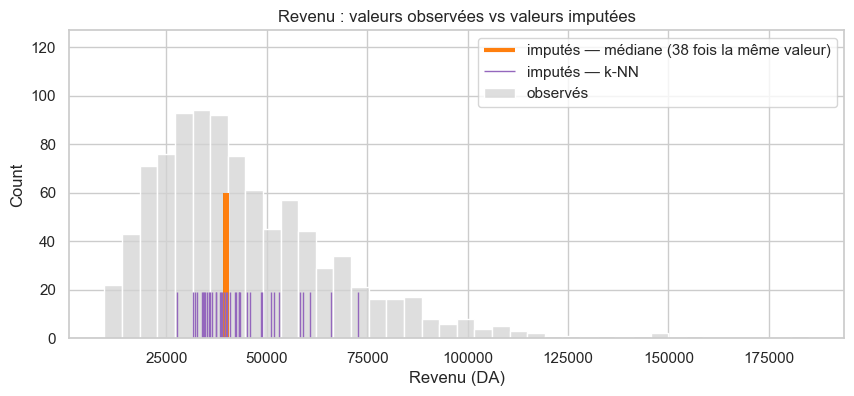

In [22]:
manquant = df["revenu"].isna()

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(df["revenu"], bins=40, color="lightgray", label="observés", ax=ax)
ax.vlines(df_med.loc[manquant, "revenu"], 0, 60, color="tab:orange", lw=3, label="imputés — médiane (38 fois la même valeur)")
sns.rugplot(df_knn.loc[manquant, "revenu"], color="tab:purple", height=0.15, lw=2, label="imputés — k-NN", ax=ax)
ax.set_title("Revenu : valeurs observées vs valeurs imputées")
ax.set_xlabel("Revenu (DA)")
ax.legend()
plt.show()

**Réponses attendues**
1. `mean()` **ignore déjà les NaN** : le « brut » est calculé sur les 950 revenus connus, exactement comme après `dropna()`. Mais la suppression **jette 38 clients entiers** (âge, ancienneté, segment… valides) : perte d'information, et biais si les NaN ne sont pas répartis au hasard (MAR / MNAR). Ici les NaN du TP 1 ont été tirés au hasard (MCAR), c'est pour cela que la moyenne ne bouge pas.
2. Le revenu est **asymétrique à droite** : médiane (≈ 39 750 DA) < moyenne (≈ 44 700 DA). Remplacer 38 valeurs par la médiane tire la moyenne vers le bas. Et 38 valeurs **identiques** créent un pic artificiel → la dispersion (écart-type) est **sous-estimée**.
3. **k-NN** : il garde les 988 lignes, déforme moins la moyenne et l'écart-type, et produit des valeurs **variées** qui dépendent du profil du client. La médiane reste un bon choix par défaut, simple et robuste, quand le taux de manquants est faible.

⚠️ Les chiffres diffèrent de ceux de la diapositive (données d'illustration), mais le **classement** est le même : k-NN est le plus proche de la référence, puis la médiane.

### 2.4 Pour aller plus loin — évaluer vraiment l'imputation
Comparer des moyennes ne dit pas si les valeurs imputées sont **justes**. Méthode classique : **cacher** des valeurs qu'on connaît, les imputer, puis mesurer l'erreur.

1. Cachez 100 revenus **connus** (tirés au hasard, graine 0).
2. Imputez avec la médiane, le k-NN brut, et le k-NN sur données **standardisées** (`StandardScaler`, section 6 du cours).
3. Comparez l'**erreur absolue moyenne** (MAE) entre valeurs imputées et vraies valeurs.

In [23]:
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(0)
cache = rng.choice(df.index[df["revenu"].notna()], size=100, replace=False)
vrais = df.loc[cache, "revenu"]

test = df[num_cols].copy()
test.loc[cache, "revenu"] = np.nan

def mae(rempli):
    """Erreur absolue moyenne sur les 100 revenus cachés."""
    return (rempli.loc[cache, "revenu"] - vrais).abs().mean()

def en_df(tableau):
    return pd.DataFrame(tableau, columns=num_cols, index=test.index)

def knn_standardise(X):
    """Standardiser -> k-NN -> revenir à l'échelle d'origine."""
    sc = StandardScaler()
    rempli = sc.inverse_transform(KNNImputer(n_neighbors=5).fit_transform(sc.fit_transform(X)))
    return pd.DataFrame(rempli, columns=X.columns, index=X.index)

avec_segment = pd.concat([test, pd.get_dummies(df["segment"], dtype=float)], axis=1)   # one-hot (section 7)

resultats = {
    "Médiane": mae(en_df(SimpleImputer(strategy="median").fit_transform(test))),
    "k-NN brut": mae(en_df(KNNImputer(n_neighbors=5).fit_transform(test))),
    "k-NN standardisé": mae(knn_standardise(test)),
    "k-NN standardisé + segment": mae(knn_standardise(avec_segment)),
    "Médiane par segment": mae(test.assign(revenu=test["revenu"].fillna(
        test.groupby(df["segment"])["revenu"].transform("median")))),
}
pd.Series(resultats, name="MAE (DA)").round(0)

Médiane                       19201.0
k-NN brut                     18509.0
k-NN standardisé              18184.0
k-NN standardisé + segment    16227.0
Médiane par segment           15757.0
Name: MAE (DA), dtype: float64

**Réponse attendue** (MAE sur 100 revenus cachés)

| Méthode | MAE ≈ |
|---|---|
| Médiane globale | 19 200 DA |
| k-NN brut | 18 500 DA |
| k-NN standardisé | 18 200 DA |
| k-NN standardisé + segment | 16 200 DA |
| Médiane par segment | 15 800 DA |

- Le k-NN fait un peu mieux que la médiane : ses voisins sont choisis sur `nb_achats`, qui est corrélé au revenu (r ≈ 0,29).
- **Sans standardisation**, la distance est dominée par les variables aux plus grandes valeurs (âge, ancienneté), qui n'ont **aucun lien** avec le revenu → voisins peu pertinents. Standardiser donne le même poids à chaque variable (section 6).
- Le gain le plus net vient du **segment**, très lié au revenu (A ≫ B > C). Une simple **médiane par segment** fait même mieux que le k-NN : **la bonne information compte plus que l'algorithme**.
- Leçon de méthode : on ne juge pas une imputation sur la moyenne obtenue, mais sur l'**erreur** mesurée sur des valeurs connues.

### 2.5 Choix final et sauvegarde
On retient le **k-NN** : on remplace le revenu de `df` par celui de `df_knn`, puis on sauvegarde `clients_nettoye.csv` (réutilisé à l'étape 3).

In [24]:
df_nettoye = df.copy()
df_nettoye["revenu"] = df_knn["revenu"].round(-2)   # même précision que les données d'origine

df_nettoye.to_csv("clients_nettoye.csv", sep=";", index=False, encoding="utf-8")
df_nettoye.shape

(988, 8)

✅ **Auto-correction**

In [25]:
assert df_nettoye.shape == (988, 8) and df_nettoye.isna().sum().sum() == 0
assert (df_nettoye["revenu"] % 100 == 0).all(), "revenus arrondis à la centaine"
print("✅ 2.5 correct — clients_nettoye.csv sauvegardé")

✅ 2.5 correct — clients_nettoye.csv sauvegardé


---
## Étape 3 — Visualiser avec Matplotlib et Seaborn
*Trois graphiques suffisent pour l'essentiel du diagnostic.*

| Graphique | Rôle |
|---|---|
| 1. **Histogramme** | forme de la distribution, asymétrie, outliers |
| 2. **Boxplot** | comparer le revenu entre segments (médiane, IQR, valeurs aberrantes) |
| 3. **Heatmap** | corrélations linéaires ; \|r\| > 0,8 → redondance potentielle |

Sur `df_nettoye`, tracez les trois graphiques **côte à côte** (`plt.subplots(1, 3, figsize=(18, 4))`), avec titres et étiquettes d'axes.

⚠️ `sns.distplot` est déprécié → utiliser `sns.histplot` (ou `ax.hist`).

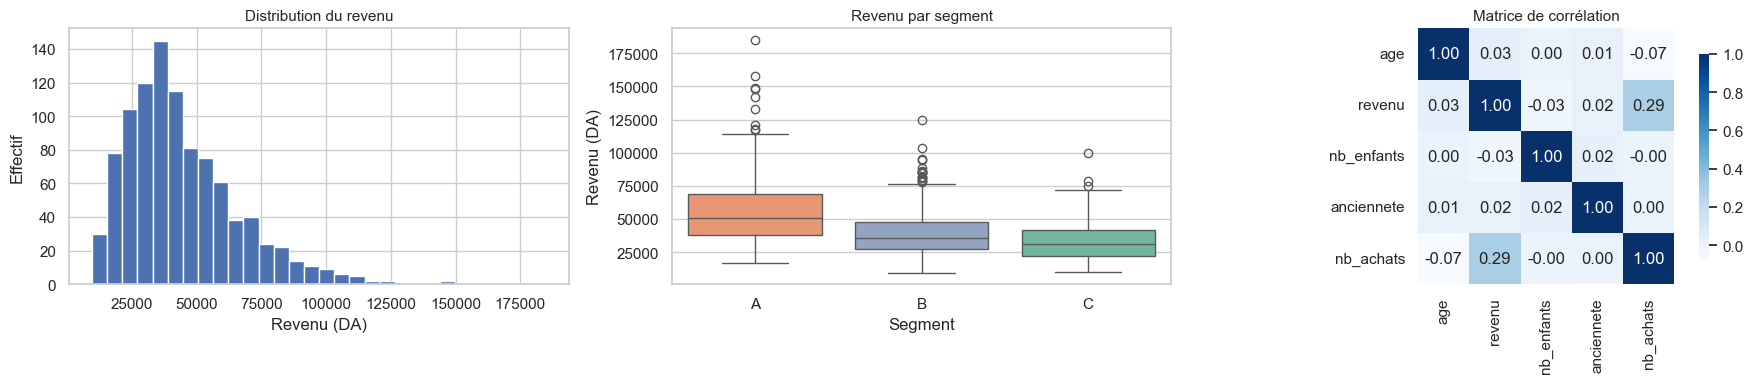

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# 1. Histogramme : forme et outliers
axes[0].hist(df_nettoye["revenu"], bins=30, color="#4C72B0", edgecolor="white")
axes[0].set_title("Distribution du revenu", fontsize=11)
axes[0].set_xlabel("Revenu (DA)")
axes[0].set_ylabel("Effectif")

# 2. Boxplot : comparaison par segment
sns.boxplot(data=df_nettoye, x="segment", y="revenu", order=["A", "B", "C"],
            hue="segment", palette="Set2", legend=False, ax=axes[1])
axes[1].set_title("Revenu par segment", fontsize=11)
axes[1].set_xlabel("Segment")
axes[1].set_ylabel("Revenu (DA)")

# 3. Heatmap de corrélation (variables numériques, sans id)
sns.heatmap(df_nettoye[num_cols].corr(), annot=True, cmap="Blues", fmt=".2f",
            ax=axes[2], square=True, cbar_kws={"shrink": 0.8})
axes[2].set_title("Matrice de corrélation", fontsize=11)

plt.tight_layout()
plt.show()

**Constats attendus**
1. **Histogramme** : distribution **asymétrique à droite** (skewness ≈ 1,4) — la plupart des clients entre 20 000 et 60 000 DA, une longue queue jusqu'à ≈ 185 000 DA. Ces grands revenus sont plausibles (ce ne sont plus des erreurs, le code 999 999 a été traité).
2. **Boxplot** : le segment **A** a le revenu le plus élevé (médiane ≈ 51 000 DA), devant **B** (≈ 36 000) et **C** (≈ 31 000). Les boîtes de B et C se chevauchent largement ; chaque segment a des valeurs au-delà de la moustache (asymétrie).
3. **Heatmap** : la seule corrélation notable est **revenu – nb_achats (r ≈ 0,29)**, faible à modérée. Toutes les autres sont proches de 0. Aucune paire avec |r| > 0,8 → **pas de redondance**, on garde toutes les variables.

💡 *À rappeler* : une corrélation proche de 0 n'exclut pas une relation **non linéaire**, et corrélation ≠ causalité.

---
## Étape 4 — Documenter chaque décision
*Livrable : notebook complété + conclusions. Traçabilité et reproductibilité.*

**Journal des décisions (attendu)**

| # | Problème détecté | Décision | Justification | Lignes avant → après |
|---|---|---|---|---|
| 1 | 12 doublons exacts | `drop_duplicates(keep="first")` | un client compté deux fois fausse tous les effectifs et moyennes | 1 012 → 1 000 |
| 2 | Segments `a` / `b` en minuscules (60 lignes) | `replace({"a": "A", "b": "B"})` | sinon 5 modalités au lieu de 3 | 1 000 → 1 000 |
| 3 | `age` en texte : 4 valeurs illisibles | `to_numeric(errors="coerce")` | rend la colonne numérique, l'illisible devient NaN | 1 000 → 1 000 |
| 4 | 8 âges hors plage (−3, 150, 999…) + 4 NaN | `between(0, 120)` | âge irréaliste → fiche peu fiable, 1,2 % des lignes | 1 000 → 988 |
| 5 | Revenu = 999 999 (code d'erreur) | remplacé par NaN | seule la case est fausse, on garde le client | 988 → 988 |
| 6 | 38 revenus manquants (3,8 %) | imputation **k-NN (k = 5)**, arrondi à la centaine | garde toutes les lignes, déforme le moins la distribution | 988 → 988 |

**Conclusions (exemple)**
- Le fichier brut contenait 4 types de défauts (doublons, modalités, format, plages). Après nettoyage : **988 clients, 8 variables, 0 valeur manquante**.
- Les trois méthodes d'imputation donnent des moyennes proches (< 0,5 % d'écart) car le taux de manquants est faible ; la médiane écrase la dispersion, le k-NN la préserve mieux.
- Le revenu est asymétrique à droite et dépend nettement du **segment** (A > B > C). Aucune paire de variables n'est redondante (|r| < 0,8).
- **Limites** : le k-NN n'utilise que les variables numériques non standardisées ; le segment, très lié au revenu, pourrait être ajouté (encodage one-hot, section 7) pour améliorer l'imputation.
- **Reproductibilité** : en relançant le notebook du début à la fin (*Kernel → Restart & Run All*), on obtient exactement le même `clients_nettoye.csv`.

---
## Bilan

| Étape | Commande | Ce qu'on a appris |
|---|---|---|
| Doublons | `duplicated()`, `drop_duplicates()` | compter **avant** de supprimer |
| Modalités | `replace()`, `value_counts()` | harmoniser **avant** d'analyser |
| Types | `pd.to_numeric(errors="coerce")` | l'illisible devient NaN, traité ensuite |
| Plages | `between()` | valider les valeurs réalistes |
| Manquants | `dropna()`, `SimpleImputer`, `KNNImputer` | comparer les méthodes, pas seulement les moyennes |
| Visualisation | `hist`, `sns.boxplot`, `sns.heatmap` | distribution, groupes, corrélations |

Ordre à respecter : **Dédupliquer → Harmoniser → Typer → Valider les plages → Imputer → Visualiser**.